## LangGraph - zachowanie stanu i human-in-the-loop

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/pl/8_5_LangGraph_persistence_and_HITL.ipynb)

| | |
|---|---|
| 🎯 **Czego się nauczysz** | Checkpointing (InMemorySaver, SqliteSaver), historia stanu, wznawianie po awarii, time travel (replay i fork) oraz human-in-the-loop z `interrupt()` i `Command(resume=...)`: zatwierdź / edytuj / odrzuć, pętle walidacji, przerwania wewnątrz narzędzi i równoległe przerwania. |
| 🔑 **Klucze API** | `OPENAI_API_KEY` |
| 💲 **Koszt API** | bardzo niski – kilka krótkich zapytań |
| ⏱️ **Czas wykonania** | < 1 min |

### Instalacja bibliotek

In [1]:
# Zainstaluj bezpośrednie zależności używane w tym notebooku.
# Pomijane, gdy brak pip, np. w środowisku `uv sync`, które ma je już zainstalowane (zob. README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langgraph-checkpoint-sqlite langchain langchain-openai pandas python-dotenv
# Google Colab: dodaj OPENAI_API_KEY w panelu Secrets (🔑) i zezwól notatnikowi na dostęp.
# Odkomentuj te linie, aby wczytać klucz z Colab Secrets do bieżącej sesji:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Lokalnie umieść OPENAI_API_KEY=... w pliku .env; nie commituj klucza.

Note: you may need to restart the kernel to use updated packages.


In [2]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(model="gpt-6.1-terra", reasoning_effort="none")

## 1. Checkpointing – jak LangGraph zapamiętuje stan

Gdy graf jest skompilowany z **checkpointerem**, LangGraph zapisuje migawkę stanu (**checkpoint**) po każdym kroku (*super-step*). Checkpointy są grupowane w **wątki** (*threads*) identyfikowane przez `thread_id`.

```
invoke(input, thread_id="order-1")
   │
   ▼
[validate] ──► 💾 ──► [price] ──► 💾 ──► [discount] ──► 💾
             checkpoint          checkpoint             checkpoint
```

Ten jeden mechanizm daje nam wszystko, co pokazuje ten notebook:

| Możliwość | Co wykorzystuje z checkpointów |
|---|---|
| Pamięć rozmowy | kontynuacja tego samego wątku nową wiadomością |
| Odporność na awarie | wznowienie od ostatniego udanego kroku po awarii |
| Time travel | odtworzenie lub rozgałęzienie od dowolnego wcześniejszego checkpointu |
| Human-in-the-loop | wstrzymanie grafu, czekanie (sekundy lub dni), wznowienie |

| Pojęcie | Znaczenie |
|---|---|
| `thread_id` | identyfikator jednej rozmowy / procesu / sprawy |
| checkpoint | migawka stanu po super-kroku (`StateSnapshot`) |
| checkpointer | miejsce przechowywania: `InMemorySaver`, `SqliteSaver`, `PostgresSaver`, … |

Zaczynamy od deterministycznego grafu obsługi zamówienia – do zrozumienia persystencji LLM nie jest potrzebny.

In [3]:
import operator
from typing import Annotated, TypedDict

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph


class OrderState(TypedDict, total=False):
    item: str
    quantity: int
    total: float
    log: Annotated[list[str], operator.add]  # reducer: nowe wpisy są doklejane


PRICES = {"keyboard": 120.0, "mouse": 40.0, "monitor": 900.0}


def validate(state: OrderState) -> OrderState:
    if state["item"] not in PRICES:
        raise ValueError(f"nieznany produkt: {state['item']}")
    return {"log": [f"zweryfikowano {state['quantity']} x {state['item']}"]}


def price(state: OrderState) -> OrderState:
    total = PRICES[state["item"]] * state["quantity"]
    return {"total": total, "log": [f"wycena: {total:.2f}"]}


def discount(state: OrderState) -> OrderState:
    total = round(state["total"] * (0.9 if state["total"] > 500 else 1.0), 2)
    return {"total": total, "log": [f"po rabacie: {total:.2f}"]}


def build_order_graph(checkpointer):
    builder = StateGraph(OrderState)
    builder.add_node(validate)
    builder.add_node(price)
    builder.add_node(discount)
    builder.add_edge(START, "validate")
    builder.add_edge("validate", "price")
    builder.add_edge("price", "discount")
    builder.add_edge("discount", END)
    return builder.compile(checkpointer=checkpointer)


order_graph = build_order_graph(InMemorySaver())
config = {"configurable": {"thread_id": "order-1"}}
order_graph.invoke({"item": "keyboard", "quantity": 5}, config)

{'item': 'keyboard',
 'quantity': 5,
 'total': 540.0,
 'log': ['zweryfikowano 5 x keyboard', 'wycena: 600.00', 'po rabacie: 540.00']}

### Bieżący stan i historia stanu

`get_state` zwraca najnowszy `StateSnapshot`; `get_state_history` zwraca wszystkie checkpointy wątku, **od najnowszego**.

In [4]:
import pandas as pd

snapshot = order_graph.get_state(config)
print("values:", snapshot.values)
print("next:  ", snapshot.next)  # () = graf zakończył działanie


def history_table(graph, config) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "step": s.metadata["step"],
            "source": s.metadata["source"],
            "next": s.next,
            "total": s.values.get("total"),
            "checkpoint_id": s.config["configurable"]["checkpoint_id"][-8:],
        }
        for s in graph.get_state_history(config)
    )


history_table(order_graph, config)

values: {'item': 'keyboard', 'quantity': 5, 'total': 540.0, 'log': ['zweryfikowano 5 x keyboard', 'wycena: 600.00', 'po rabacie: 540.00']}
next:   ()


,step,source,next,total,checkpoint_id
0,3,loop,(),540.0,49d3ad65
1,2,loop,"(discount,)",600.0,0bcafd0c
2,1,loop,"(price,)",NaN,292749d9
3,0,loop,"(validate,)",NaN,13e752d2
4,-1,input,"(__start__,)",NaN,b68bd1c1


Wątki są od siebie całkowicie odizolowane – inny `thread_id` to inne zamówienie:

In [5]:
order_graph.invoke({"item": "mouse", "quantity": 2}, {"configurable": {"thread_id": "order-2"}})
for thread in ["order-1", "order-2"]:
    print(thread, "->", order_graph.get_state({"configurable": {"thread_id": thread}}).values["log"])

order-1 -> ['zweryfikowano 5 x keyboard', 'wycena: 600.00', 'po rabacie: 540.00']
order-2 -> ['zweryfikowano 2 x mouse', 'wycena: 80.00', 'po rabacie: 80.00']


## 2. Durable execution – SqliteSaver i wznawianie po awarii

`InMemorySaver` znika razem z procesem Pythona. W prawdziwych aplikacjach checkpointer zapisuje do bazy danych: `SqliteSaver` (lokalnie, jeden proces) lub `PostgresSaver` (produkcja). API jest identyczne.

Scenariusz: proces zamówienia, w którym **API płatności nie działa**. Graf ulega awarii w `charge_card`. Następnie „restartujemy aplikację” – nowe połączenie z bazą, nowy obiekt grafu – i kontynuujemy ten sam wątek. Dzięki checkpointom **kroki, które już się udały, nie są wykonywane ponownie** (brak podwójnej rezerwacji towaru!).

`durability="sync"` sprawia, że LangGraph zapisuje każdy checkpoint przed rozpoczęciem kolejnego kroku (najbezpieczniejszy tryb; domyślny `"async"` zapisuje w tle, a `"exit"` dopiero na końcu).

In [6]:
import sqlite3
import tempfile
from collections import Counter
from pathlib import Path

from langgraph.checkpoint.sqlite import SqliteSaver

DB_PATH = Path(tempfile.gettempdir()) / "langgraph_checkpoints.sqlite"
for suffix in ("", "-wal", "-shm"):  # stale WAL/shm files cause "disk I/O error"
    Path(f"{DB_PATH}{suffix}").unlink(missing_ok=True)  # zaczynamy demo od czystej bazy

calls = Counter()  # ile razy każdy węzeł faktycznie się wykonał
payment_api_up = False


class PaymentState(TypedDict, total=False):
    order_id: str
    log: Annotated[list[str], operator.add]


def reserve_stock(state: PaymentState) -> PaymentState:
    calls["reserve_stock"] += 1
    return {"log": ["zarezerwowano towar"]}


def charge_card(state: PaymentState) -> PaymentState:
    calls["charge_card"] += 1
    if not payment_api_up:
        raise ConnectionError("API płatności niedostępne")
    return {"log": ["obciążono kartę"]}


def send_confirmation(state: PaymentState) -> PaymentState:
    calls["send_confirmation"] += 1
    return {"log": ["wysłano e-mail z potwierdzeniem"]}


def build_payment_graph(checkpointer):
    builder = StateGraph(PaymentState)
    builder.add_node(reserve_stock)
    builder.add_node(charge_card)
    builder.add_node(send_confirmation)
    builder.add_edge(START, "reserve_stock")
    builder.add_edge("reserve_stock", "charge_card")
    builder.add_edge("charge_card", "send_confirmation")
    builder.add_edge("send_confirmation", END)
    return builder.compile(checkpointer=checkpointer)


config = {"configurable": {"thread_id": "order-1001"}}

# --- pierwsze uruchomienie aplikacji
connection = sqlite3.connect(DB_PATH, check_same_thread=False)
graph = build_payment_graph(SqliteSaver(connection))
try:
    graph.invoke({"order_id": "1001"}, config, durability="sync")
except ConnectionError as error:
    print("💥 awaria:", error)
print("następny krok zapisany w bazie:", graph.get_state(config).next)
connection.close()  # proces „umiera”

💥 awaria: API płatności niedostępne
następny krok zapisany w bazie: ('charge_card',)


In [7]:
# --- restart aplikacji: nowe połączenie, nowy obiekt grafu, API płatności znów działa
payment_api_up = True
connection = sqlite3.connect(DB_PATH, check_same_thread=False)
graph = build_payment_graph(SqliteSaver(connection))

result = graph.invoke(None, config, durability="sync")  # None = kontynuuj od ostatniego checkpointu
print("log:  ", result["log"])
print("calls:", dict(calls))
assert calls["reserve_stock"] == 1  # towar NIE został zarezerwowany dwa razy

log:   ['zarezerwowano towar', 'obciążono kartę', 'wysłano e-mail z potwierdzeniem']
calls: {'reserve_stock': 1, 'charge_card': 2, 'send_confirmation': 1}


💡 W produkcji dodaj `RetryPolicy` do zawodnych węzłów (`builder.add_node(charge_card, retry_policy=RetryPolicy(max_attempts=3))`) – ponowienia radzą sobie z krótkimi zakłóceniami, a checkpointy z długimi awariami i restartami.

## 3. Time travel – replay i fork

Każdy checkpoint ma własny `checkpoint_id`, więc możemy cofnąć się w czasie:

- **Replay** – `invoke(None, past_config)` uruchamia graf ponownie od wcześniejszego checkpointu.
- **Fork** – `update_state(past_config, new_values)` tworzy nowy checkpoint odgałęziony od wcześniejszego, ze zmienionym stanem; graf kontynuuje od tego miejsca. Oryginalna historia pozostaje nietknięta.

Typowe zastosowania: debugowanie („co, gdyby LLM zwrócił coś innego?”), poprawianie błędnego kroku, badanie alternatyw.

In [8]:
config = {"configurable": {"thread_id": "order-1"}}

# checkpoint tuż przed wykonaniem `discount` (historia jest od najnowszego)
before_discount = next(s for s in order_graph.get_state_history(config) if s.next == ("discount",))
print("stan przed rabatem:", before_discount.values["total"])

# FORK: co, gdyby klient zamówił 20 klawiatur?
fork_config = order_graph.update_state(before_discount.config, {"quantity": 20, "total": 20 * PRICES["keyboard"]})
forked = order_graph.invoke(None, fork_config)
print("suma w forku:      ", forked["total"])

history_table(order_graph, config)

stan przed rabatem: 600.0
suma w forku:       2160.0


,step,source,next,total,checkpoint_id
0,4,loop,(),2160.0,513ee35f
1,3,update,"(discount,)",2400.0,47010ceb
2,3,loop,(),540.0,49d3ad65
3,2,loop,"(discount,)",600.0,0bcafd0c
4,1,loop,"(price,)",NaN,292749d9
5,0,loop,"(validate,)",NaN,13e752d2
6,-1,input,"(__start__,)",NaN,b68bd1c1


Historia zawiera teraz obie gałęzie: oryginalny przebieg (suma 540.0) i fork (`source = update`, a po nim nowy krok `discount`, suma 2160.0). Najnowszym checkpointem wątku jest fork.

## 4. Human-in-the-loop z `interrupt()`

`interrupt(payload)` wywołane w węźle **wstrzymuje graf**, zapisuje checkpoint i zwraca `payload` do wywołującego. Człowiek może odpowiedzieć od razu albo za tydzień – stan czeka w checkpointerze. `Command(resume=value)` uruchamia ponownie wstrzymany węzeł i tym razem `interrupt()` **zwraca** `value`.

```
draft_decision ──► human_review ──interrupt()──► ⏸ czeka na człowieka (stan w checkpointerze)
                                                    │
                     Command(resume={"action": ...}) │
                                                    ▼
                   human_review wznawia ──► execute_refund / notify_rejection
```

Klasyczne wzorce: **zatwierdź / edytuj / odrzuć**, **przegląd i edycja stanu**, **walidacja danych od człowieka**, **zatwierdzanie wywołań narzędzi**.

> `HumanInTheLoopMiddleware` dla `create_agent` (notebook 3_4) to gotowa, deklaratywna wersja tego samego mechanizmu. Tutaj używamy `interrupt()` bezpośrednio – działa w dowolnym grafie i dowolnym węźle.

### 4.1 Zatwierdź / edytuj / odrzuć decyzję LLM

In [9]:
from typing import Literal

from langgraph.types import Command, interrupt
from pydantic import BaseModel, Field


class RefundDecision(BaseModel):
    approve: bool
    amount: float = Field(description="Proponowana kwota zwrotu")
    reason: str = Field(description="Uzasadnienie w jednym zdaniu, po polsku")


class RefundState(TypedDict, total=False):
    request: str
    order_total: float
    decision: dict
    status: str


def draft_decision(state: RefundState) -> RefundState:
    decision = llm.with_structured_output(RefundDecision).invoke(
        "Polityka zwrotów: zwroty do 30 dni; za wadliwe produkty pełny zwrot; "
        "zwrot nigdy nie przekracza wartości zamówienia.\n"
        f"Wartość zamówienia: {state['order_total']}\nProśba klienta: {state['request']}\n"
        "Zaproponuj decyzję w sprawie zwrotu."
    )
    return {"decision": decision.model_dump()}


def human_review(state: RefundState) -> Command[Literal["execute_refund", "notify_rejection"]]:
    answer = interrupt({"task": "Sprawdź propozycję zwrotu", "proposal": state["decision"]})
    if answer["action"] == "approve":
        return Command(goto="execute_refund")
    if answer["action"] == "edit":
        return Command(goto="execute_refund", update={"decision": {**state["decision"], "amount": answer["amount"]}})
    return Command(goto="notify_rejection", update={"status": f"odrzucono: {answer['comment']}"})


def execute_refund(state: RefundState) -> RefundState:
    return {"status": f"zwrócono {state['decision']['amount']:.2f}"}


def notify_rejection(state: RefundState) -> RefundState:
    return {}  # np. wyślij e-mail z state["status"]


builder = StateGraph(RefundState)
builder.add_node(draft_decision)
builder.add_node(human_review)  # routing wynika z typu zwracanego Command[...]
builder.add_node(execute_refund)
builder.add_node(notify_rejection)
builder.add_edge(START, "draft_decision")
builder.add_edge("draft_decision", "human_review")
builder.add_edge("execute_refund", END)
builder.add_edge("notify_rejection", END)
refund_graph = builder.compile(checkpointer=InMemorySaver())

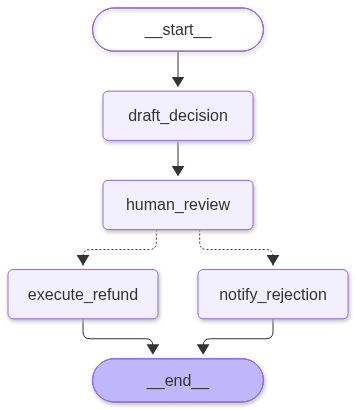

In [10]:
from IPython.display import Image

Image(refund_graph.get_graph().draw_mermaid_png())

Z `version="v2"` metoda `invoke` zwraca `GraphOutput` z dwoma polami: `.value` (stan) i `.interrupts` (oczekujące pytania do człowieka).

In [11]:
config = {"configurable": {"thread_id": "refund-1"}}
out = refund_graph.invoke(
    {"request": "Słuchawki kupione 10 dni temu przestały grać w jednym uchu.", "order_total": 399.0},
    config,
    version="v2",
)
print("wstrzymano przed:", refund_graph.get_state(config).next)
print("pytanie do człowieka:", out.interrupts[0].value)

wstrzymano przed: ('human_review',)
pytanie do człowieka: {'task': 'Sprawdź propozycję zwrotu', 'proposal': {'approve': True, 'amount': 399.0, 'reason': 'Wadliwy produkt zgłoszono w ciągu 30 dni, więc przysługuje pełny zwrot wartości zamówienia.'}}


Recenzent decyduje się zwrócić inną kwotę (**edycja**):

In [12]:
out = refund_graph.invoke(Command(resume={"action": "edit", "amount": 350.0}), config, version="v2")
print(out.value["status"], "| oczekujące przerwania:", out.interrupts)

zwrócono 350.00 | oczekujące przerwania: ()


I **odrzucenie** w innym wątku:

In [13]:
config = {"configurable": {"thread_id": "refund-2"}}
refund_graph.invoke({"request": "Chcę zwrotu pieniędzy za laptopa kupionego 3 miesiące temu, po prostu mi się nie podoba.", "order_total": 4200.0}, config)
out = refund_graph.invoke(Command(resume={"action": "reject", "comment": "poza 30-dniowym terminem"}), config, version="v2")
print(out.value["decision"]["reason"])
print(out.value["status"])

Zakup nastąpił trzy miesiące temu, więc przekroczono 30-dniowy termin zwrotu, a produkt nie został zgłoszony jako wadliwy.
odrzucono: poza 30-dniowym terminem


### 4.2 Walidacja danych od człowieka – interrupt w pętli

Węzeł może wywołać `interrupt()` wiele razy. Przy każdym wznowieniu węzeł uruchamia się od początku, a wcześniejsze wywołania `interrupt()` **zwracają zapisane odpowiedzi w tej samej kolejności**, więc prosta pętla `while` pyta tak długo, aż dane będą poprawne.

In [14]:
from datetime import date


class DeliveryState(TypedDict, total=False):
    delivery_date: str


def ask_delivery_date(state: DeliveryState) -> DeliveryState:
    question = "Data dostawy (RRRR-MM-DD)?"
    while True:
        answer = interrupt(question)
        try:
            return {"delivery_date": date.fromisoformat(answer).isoformat()}
        except ValueError:
            question = f"'{answer}' to niepoprawna data. Użyj formatu RRRR-MM-DD."


delivery_graph = (
    StateGraph(DeliveryState)
    .add_node(ask_delivery_date)
    .add_edge(START, "ask_delivery_date")
    .compile(checkpointer=InMemorySaver())
)

config = {"configurable": {"thread_id": "delivery-1"}}
out = delivery_graph.invoke({}, config, version="v2")
for human_answer in ["w przyszły piątek", "2026-13-01", "2026-12-04"]:
    print(f"🤖 {out.interrupts[0].value}\n👤 {human_answer}")
    out = delivery_graph.invoke(Command(resume=human_answer), config, version="v2")
print("✅ zapisano:", out.value)

🤖 Data dostawy (RRRR-MM-DD)?
👤 w przyszły piątek
🤖 'w przyszły piątek' to niepoprawna data. Użyj formatu RRRR-MM-DD.
👤 2026-13-01
🤖 '2026-13-01' to niepoprawna data. Użyj formatu RRRR-MM-DD.
👤 2026-12-04
✅ zapisano: {'delivery_date': '2026-12-04'}


### 4.3 ⚠️ Najczęstsza pułapka: węzeł uruchamia się ponownie od początku

Przy wznowieniu LangGraph **nie** kontynuuje od linii z `interrupt()` – wykonuje cały węzeł od nowa. Każdy efekt uboczny umieszczony *przed* `interrupt()` wydarzy się dwa razy:

In [15]:
sent_emails = []


def notify_and_ask(state: DeliveryState) -> DeliveryState:
    sent_emails.append("otrzymaliśmy Twoje zgłoszenie")  # ❌ efekt uboczny przed interrupt()
    answer = interrupt("Zatwierdzasz?")
    return {"delivery_date": answer}


pitfall_graph = (
    StateGraph(DeliveryState)
    .add_node(notify_and_ask)
    .add_edge(START, "notify_and_ask")
    .compile(checkpointer=InMemorySaver())
)
config = {"configurable": {"thread_id": "pitfall"}}
pitfall_graph.invoke({}, config)
pitfall_graph.invoke(Command(resume="2026-12-04"), config)
print("wysłane e-maile:", len(sent_emails), sent_emails)

wysłane e-maile: 2 ['otrzymaliśmy Twoje zgłoszenie', 'otrzymaliśmy Twoje zgłoszenie']


**Zasady korzystania z `interrupt()`:**
1. Graf potrzebuje **checkpointera**, a każde wywołanie – `thread_id`.
2. Efekty uboczne umieszczaj **po** `interrupt()` albo w osobnym węźle i dbaj o ich idempotentność.
3. Nie otaczaj `interrupt()` ogólnym `try/except` – mechanizm działa przez rzucenie specjalnego wyjątku.
4. Kolejność wywołań `interrupt()` w węźle musi być deterministyczna (odpowiedzi są dopasowywane po pozycji).
5. Payload i wartość wznowienia muszą dać się serializować do JSON.

### 4.4 Interrupt wewnątrz narzędzia – zgoda na ryzykowną akcję agenta

`interrupt()` działa także wewnątrz **narzędzia** używanego przez agenta. Agent sam decyduje, *kiedy* wywołać `issue_refund`, a samo narzędzie czeka na człowieka, zanim pieniądze opuszczą konto.

In [16]:
from langchain.agents import create_agent
from langchain.tools import tool

ORDERS = {"A-17": {"item": "słuchawki", "total": 399.0, "days_ago": 10}}


@tool
def get_order(order_id: str) -> dict:
    """Zwróć szczegóły zamówienia: produkt, wartość i ile dni temu został kupiony."""
    return ORDERS.get(order_id, {"error": "nie znaleziono zamówienia"})


@tool
def issue_refund(order_id: str, amount: float) -> str:
    """Zleć zwrot pieniędzy za zamówienie."""
    # krok zatwierdzenia jest niewidoczny dla modelu – widzi on tylko końcowy wynik narzędzia
    answer = interrupt({"action": "issue_refund", "order_id": order_id, "amount": amount})
    if answer != "approve":
        return "Recenzent odrzucił zwrot. Poinformuj klienta, że sprawa wymaga ręcznej weryfikacji."
    return f"Zwrócono {amount:.2f} za zamówienie {order_id}."


support_agent = create_agent(
    llm,
    tools=[get_order, issue_refund],
    system_prompt=(
        "Jesteś agentem wsparcia klienta. Odpowiadaj po polsku. Wadliwe produkty kupione w ciągu 30 dni podlegają pełnemu zwrotowi. "
        "Sprawdź zamówienie, a gdy zwrot jest uzasadniony, od razu wywołaj issue_refund – nie proś klienta o potwierdzenie."
    ),
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": "support-1"}}
out = support_agent.invoke(
    {"messages": [{"role": "user", "content": "Zamówienie A-17: słuchawki są zepsute, proszę o zwrot pieniędzy."}]},
    config,
    version="v2",
)
print("⏸ agent wstrzymany wewnątrz narzędzia:", out.interrupts[0].value)

⏸ agent wstrzymany wewnątrz narzędzia: {'action': 'issue_refund', 'order_id': 'A-17', 'amount': 399.0}


In [17]:
out = support_agent.invoke(Command(resume="approve"), config, version="v2")
for message in out.value["messages"]:
    message.pretty_print()

================================ Human Message =================================

Zamówienie A-17: słuchawki są zepsute, proszę o zwrot pieniędzy.
================================== Ai Message ==================================

[{'arguments': '{"order_id":"A-17"}', 'call_id': 'call_99c3182dc33c4143895ad2db743174f2', 'name': 'get_order', 'type': 'function_call', 'id': 'fc_021b475b6c4dff64006b098c9b34d487d2aacedadf9f9fb595', 'status': 'completed'}]
Tool Calls:
  get_order (call_99c3182dc33c4143895ad2db743174f2)
 Call ID: call_99c3182dc33c4143895ad2db743174f2
  Args:
    order_id: A-17
================================= Tool Message =================================
Name: get_order

{"item": "słuchawki", "total": 399.0, "days_ago": 10}
================================== Ai Message ==================================

[{'arguments': '{"order_id":"A-17","amount":399.0}', 'call_id': 'call_xjeLChYeLNWWxNLokI5X3ZTV', 'name': 'issue_refund', 'type': 'function_call', 'id': 'fc_021b475b6c4dff64006

### 4.5 Równoległe przerwania – przegląd całej partii

Dzięki `Send` graf może przeglądać kilka elementów równolegle. Każda gałąź zgłasza własne przerwanie z własnym **id**; odpowiadamy na wszystkie naraz jednym `Command(resume={interrupt_id: odpowiedź, ...})`.

In [18]:
from langgraph.types import Send


class BatchState(TypedDict, total=False):
    refunds: list[dict]
    approved: Annotated[list[str], operator.add]


def fan_out(state: BatchState) -> list[Send]:
    return [Send("review_one", refund) for refund in state["refunds"]]


def review_one(refund: dict) -> BatchState:
    decision = interrupt(f"Zwrot {refund['amount']:.2f} za zamówienie {refund['order_id']}?")
    return {"approved": [refund["order_id"]] if decision == "approve" else []}


batch_graph = (
    StateGraph(BatchState)
    .add_node(review_one)
    .add_conditional_edges(START, fan_out, ["review_one"])
    .add_edge("review_one", END)
    .compile(checkpointer=InMemorySaver())
)

config = {"configurable": {"thread_id": "batch-1"}}
refunds = [{"order_id": "A-1", "amount": 50.0}, {"order_id": "A-2", "amount": 2500.0}, {"order_id": "A-3", "amount": 80.0}]
out = batch_graph.invoke({"refunds": refunds}, config, version="v2")
for pending in out.interrupts:
    print(pending.id[:8], pending.value)

# recenzent zatwierdza wszystko poniżej 1000
answers = {i.id: "approve" if float(i.value.split()[1]) < 1000 else "reject" for i in out.interrupts}
out = batch_graph.invoke(Command(resume=answers), config, version="v2")
print("zatwierdzone:", sorted(out.value["approved"]))

60cdc4a6 Zwrot 80.00 za zamówienie A-3?
d6e45e93 Zwrot 50.00 za zamówienie A-1?
0cd3c26c Zwrot 2500.00 za zamówienie A-2?
zatwierdzone: ['A-1', 'A-3']
